# 行业资金流向图：ETF 复现与 5000 万元模拟（kwunkau_day02）

**问题**：用 18 只行业 ETF 的公开数据，复现华泰证券《行业资金流向图应用于行业轮动》的两层构造，并在 5000 万元、参与率 ≤5% ADV 的约束下检验可执行性。

**数据**：baostock 行业 ETF 日线（2020-01-02–2026-10-30）+ 新浪单只 ETF 资金流（2025-02 起，用于代理校验与 2026 案例）。

**说明**：本 Notebook 通过公开仓库的 `src/` 包运行；若在 Colab 打开，首个代码单元会自动安装依赖、克隆仓库并切换目录。

## 0. 环境与路径（Colab 自适应）

In [1]:

import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    get_ipython().system("pip -q install baostock statsmodels")
    get_ipython().system("apt-get -qq install -y fonts-wqy-zenhei > /dev/null")
    repo = Path("/content/quant-research")
    if not repo.exists():
        get_ipython().system("git clone -q https://github.com/kwunkau/quant-research /content/quant-research")
    os.chdir(repo / "kwunkau_day02")
else:
    if Path("src").exists():
        pass
    elif Path("kwunkau_day02/src").exists():
        os.chdir("kwunkau_day02")

if not Path("src").exists():
    raise RuntimeError(
        "未找到项目目录。请把 kwunkau_day02 整个目录（含 src/ 与 data/raw/）上传后，"
        "在 kwunkau_day02 目录下重新运行；或使用 Google Colab 直接运行本 Notebook。"
    )

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
print("环境就绪：", "Colab" if IN_COLAB else "本地")


环境就绪： 本地


## 1. 数据

In [2]:

from src.fetch_data import fetch_etf_daily, fetch_sina_flow

try:
    daily = fetch_etf_daily()
except Exception as exc:
    raise RuntimeError(
        "ETF 日线不可用。请把 data/raw/etf_daily.csv 上传到同路径后重跑；"
        "或在可访问 baostock 的网络环境执行 python run_all.py --refresh。"
    ) from exc

meta = daily.groupby(["code", "name"]).agg(
    上市日=("date", "min"), 最新=("date", "max"), 行数=("date", "size")
)
print(f"ETF 日线：{len(daily):,} 行，{daily.code.nunique()} 只，"
      f"{daily.date.min():%Y-%m-%d} ~ {daily.date.max():%Y-%m-%d}")
meta.tail(6)


ETF 日线：30,879 行，18 只，2019-01-02 ~ 2026-10-30


,,上市日,最新,行数
code,name,,,
sh.515790,光伏ETF,2020-12-18,2026-10-30,1420
sh.515880,通信ETF,2019-09-06,2026-10-30,1730
sh.516160,新能源ETF,2021-02-04,2026-10-30,1387
sz.159611,电力ETF,2022-01-07,2026-10-30,1164
sz.159869,游戏ETF,2021-03-05,2026-10-30,1371
sz.159928,消费ETF,2019-01-02,2026-10-30,1897


## 2. 特征与可投域

In [3]:

from src.build_features import build_dataset, cross_section
from src.config import START_DATE, END_DATE

feats = build_dataset(daily)
mask = feats["mask"]
sub = mask.loc[START_DATE:END_DATE]
print(f"样本：{sub.index.min():%Y-%m-%d} ~ {sub.index.max():%Y-%m-%d}，"
      f"{len(sub):,} 个交易日")
print("每年平均可投 ETF 数：")
sub.sum(axis=1).groupby(sub.index.year).mean().round(1)


样本：2020-01-02 ~ 2026-10-30，1,653 个交易日
每年平均可投 ETF 数：


date
2020    12.5
2021    15.3
2022    17.5
2023    18.0
2024    18.0
2025    18.0
2026    18.0
dtype: float64

## 3. 行业资金流向图

流向图逐日求解；若 `data/processed/flow_micro.csv` 不存在，会重新求解（约 10–15 分钟，取决于机器）。下表是研报三个示例日期的本地结果。

In [4]:

from src.flowmap import run as run_flowmap, solve_day

fm = run_flowmap()          # 有缓存则直接读取；无缓存则逐日求解（约 10–15 分钟）
err = fm["errors"]
med = err.max_abs_err.median() * 1000
print(f"资金流向图：{len(err)} 个交易日，最大误差中位数 "
      f"{'<0.01‰' if med < 0.01 else f'{med:.2f}‰'}，"
      f"95 分位 {err.max_abs_err.quantile(.95)*1000:.2f}‰")

key = []
for d in ["2026-06-24", "2026-06-30", "2026-07-06"]:
    cs = cross_section(feats, pd.Timestamp(d))
    sol = solve_day(cs["Q"], cs["H"], cs["V"], cs["S"], n_random=5)
    b = fm["micro"].query("date == @d").set_index("code").breadth
    key.append({
        "日期": d, "标的数": len(cs["codes"]),
        "半导体广度": b.get("sh.512480"), "通信广度": b.get("sh.515880"),
        "最大误差(‰)": sol["max_abs_err"] * 1000,
    })
pd.DataFrame(key).round(4)


资金流向图：1653 个交易日，最大误差中位数 <0.01‰，95 分位 0.23‰


,日期,标的数,半导体广度,通信广度,最大误差(‰)
0,2026-06-24,18,0.7647,1.0000,0.2290
1,2026-06-30,18,0.3529,0.5882,0.1232
2,2026-07-06,18,0.5294,0.6471,0.0001


## 4. 回测与 5000 万元模拟

In [5]:

from src.backtest import build_factor_panels, run_engine
from src.analysis import perf_metrics, ic_stats

panels = build_factor_panels(feats, fm["micro"])
base, comp = panels["base_w20"], panels["composite_w20"]

gross_base = run_engine(feats, base, cost=False, cap=False)
gross_comp = run_engine(feats, comp, cost=False, cap=False)
bench = run_engine(feats, base, cost=False, cap=False, benchmark=True)
net_comp = run_engine(feats, comp, capital=50_000_000, cost=True, cap=True)

rows = []
for label, res in [("基础因子（毛）", gross_base), ("综合因子（毛）", gross_comp),
                   ("等权基准（毛）", bench), ("综合因子（5000万净）", net_comp)]:
    m = perf_metrics(res["nav"])
    rows.append({"组合": label, "年化": m["cagr"], "波动": m["vol"],
                 "夏普": m["sharpe"], "最大回撤": m["mdd"],
                 "期末(万元)": m["final_value"] / 1e4})
pd.DataFrame(rows).round(4)


,组合,年化,波动,夏普,最大回撤,期末(万元)
0,基础因子（毛）,0.0529,0.2339,0.3465,-0.4415,7106.6807
1,综合因子（毛）,0.0812,0.2226,0.4767,-0.2938,8519.5751
2,等权基准（毛）,0.0486,0.2085,0.3415,-0.3942,6914.4600
3,综合因子（5000万净）,0.0300,0.2445,0.2481,-0.5191,6118.8464


In [6]:

ic_rows = []
for label, fac in [("基础因子", base), ("综合因子", comp)]:
    s = ic_stats(fac, mask, feats["close"].ffill())
    ic_rows.append({"因子": label, "RankIC": s["mean_ic"], "t值": s["ic_t"],
                    "IC>0占比": s["positive_share"]})
pd.DataFrame(ic_rows).round(4)


,因子,RankIC,t值,IC>0占比
0,基础因子,0.0441,2.5410,0.5845
1,综合因子,0.0159,1.0196,0.5616


In [7]:

cap_rows = []
for aum in [10_000_000, 30_000_000, 50_000_000, 100_000_000, 200_000_000, 500_000_000]:
    r = run_engine(feats, comp, capital=aum, cost=True, cap=True)
    m = perf_metrics(r["nav"])
    cap_rows.append({"资金(万元)": aum / 1e4, "年化": m["cagr"],
                     "最大回撤": m["mdd"], "成本拖累": m["cost_drag_annual"],
                     "最大参与率": m["max_participation"], "受限天数": m["binding_days"]})
pd.DataFrame(cap_rows).round(4)


,资金(万元),年化,最大回撤,成本拖累,最大参与率,受限天数
0,1000.0,0.0416,-0.5099,0.0161,0.021,0
1,3000.0,0.0336,-0.5198,0.0222,0.050,8
2,5000.0,0.0300,-0.5191,0.0246,0.050,125
3,10000.0,0.0322,-0.4929,0.0244,0.050,273
4,20000.0,0.0372,-0.4693,0.0215,0.050,329
5,50000.0,0.0428,-0.4629,0.0141,0.050,346


## 5. 2026 年复盘

In [8]:

import json
from src.config import OUTPUT

res = json.loads((OUTPUT / "results.json").read_text(encoding="utf-8"))
ytd = pd.DataFrame(res["review_2026"]["ytd"])
ytd["ytd"] = (ytd["ytd"] * 100).round(1)
ytd.head(8)


,code,name,ytd
0,sh.515220,煤炭ETF,20.4
1,sh.512800,银行ETF,8.5
2,sz.159611,电力ETF,2.5
3,sh.512010,医药ETF,-0.3
4,sh.512170,医疗ETF,-1.5
5,sh.512480,半导体ETF,-1.6
6,sz.159928,消费ETF,-14.8
7,sh.515880,通信ETF,-15.9


## 6. 图表

[charts] fig1_nav.png


[charts] fig2_flowmap.png


[charts] fig3_review2026.png


[charts] fig4_capacity.png


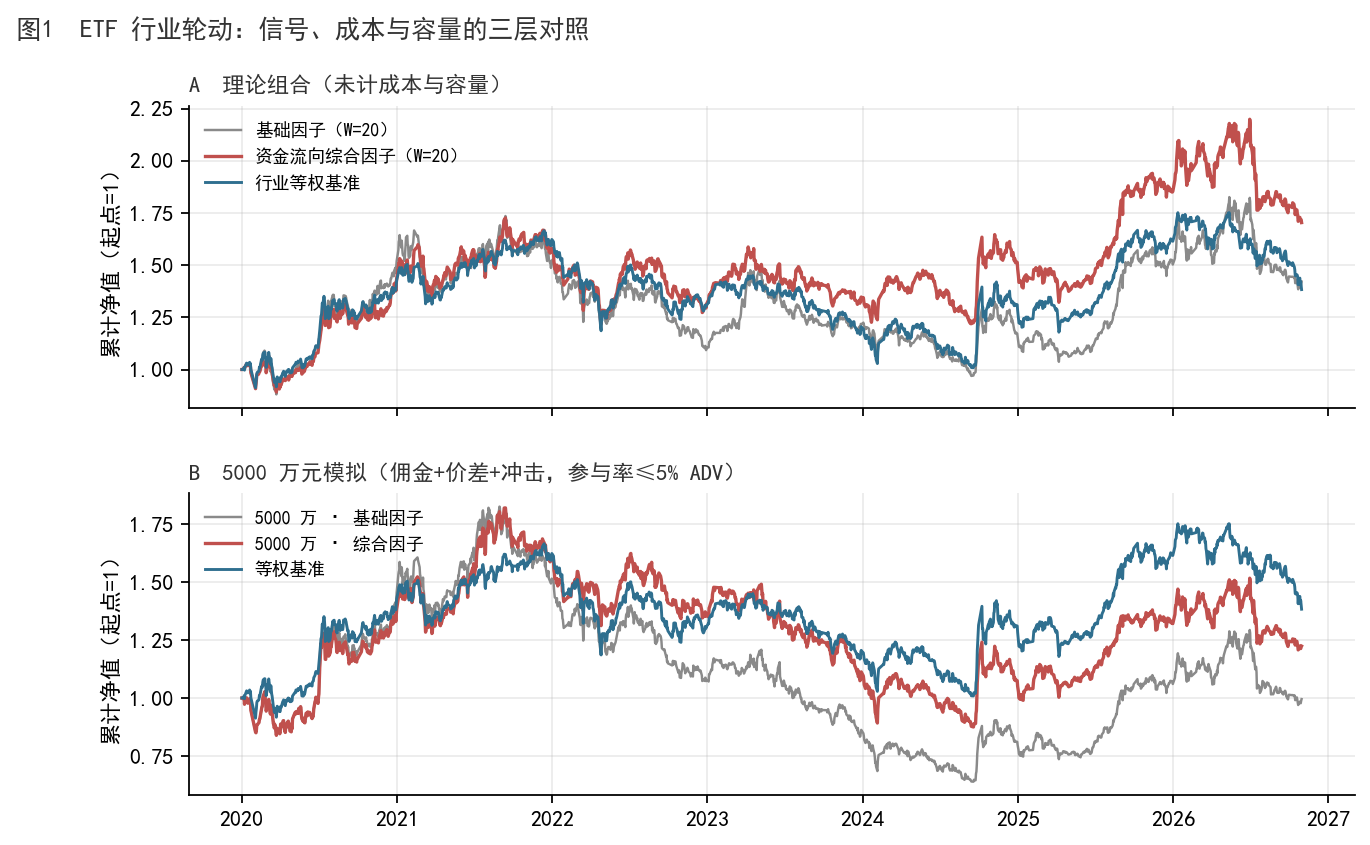

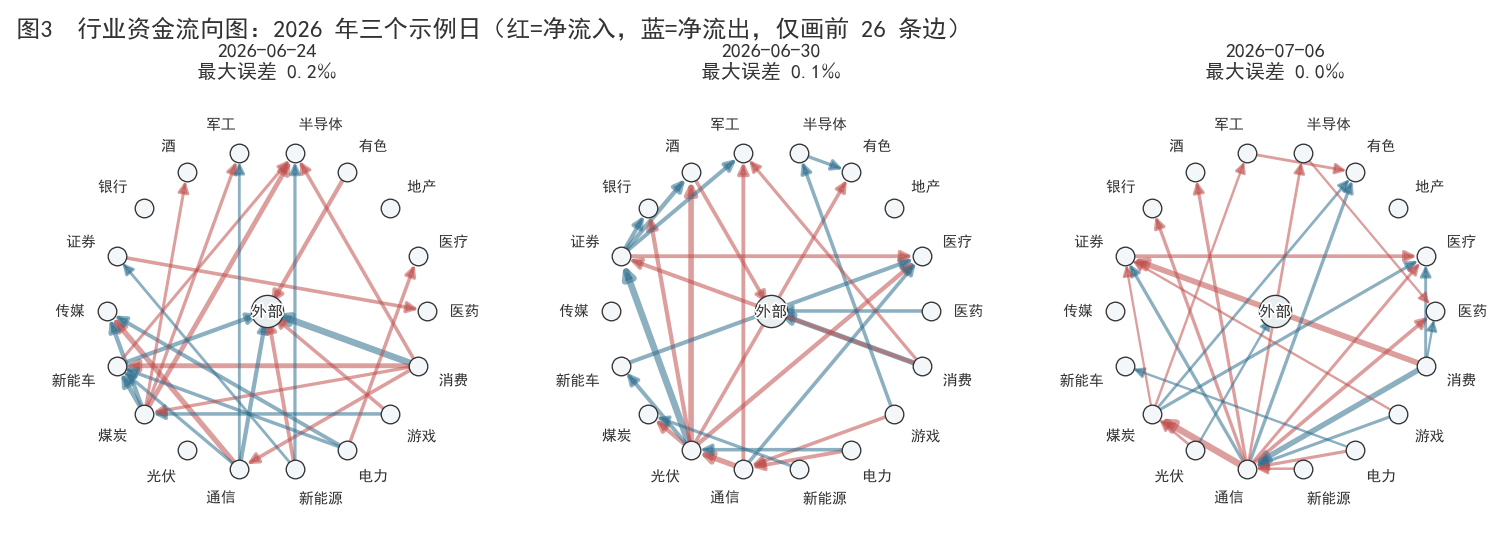

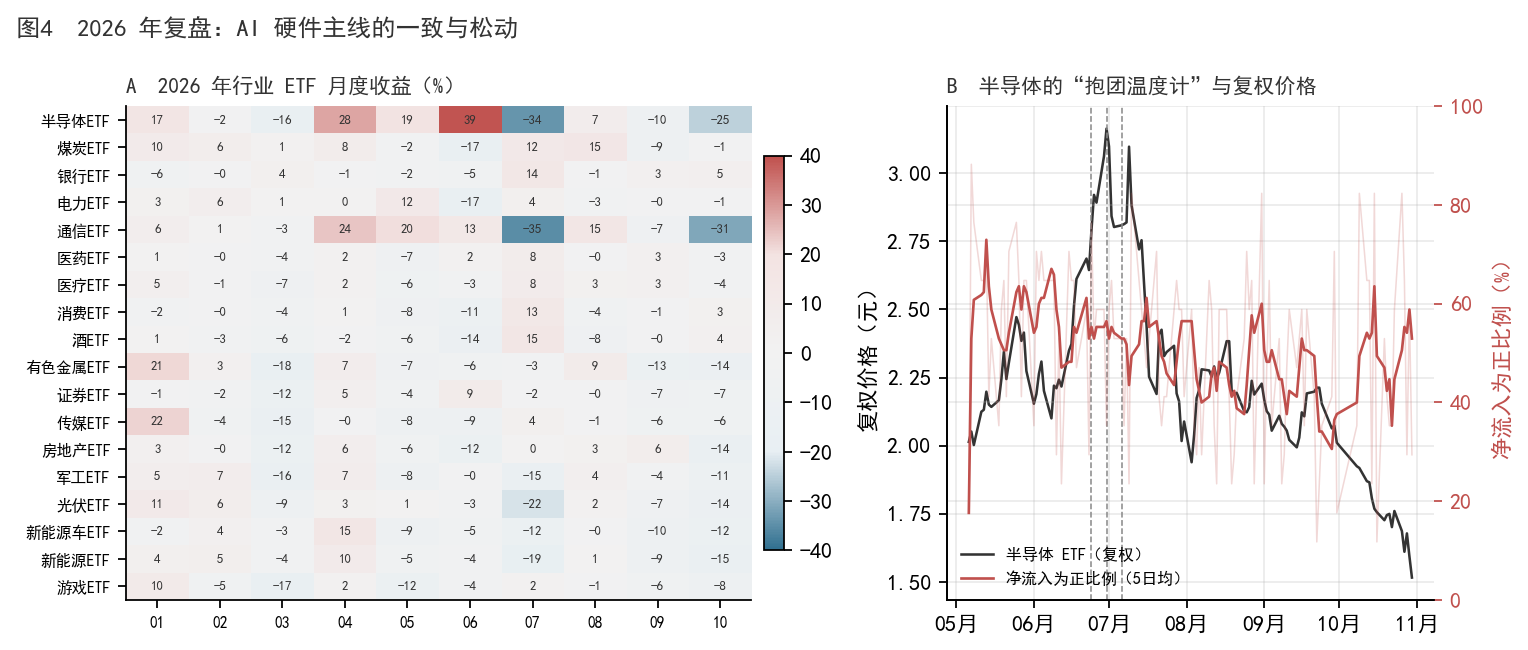

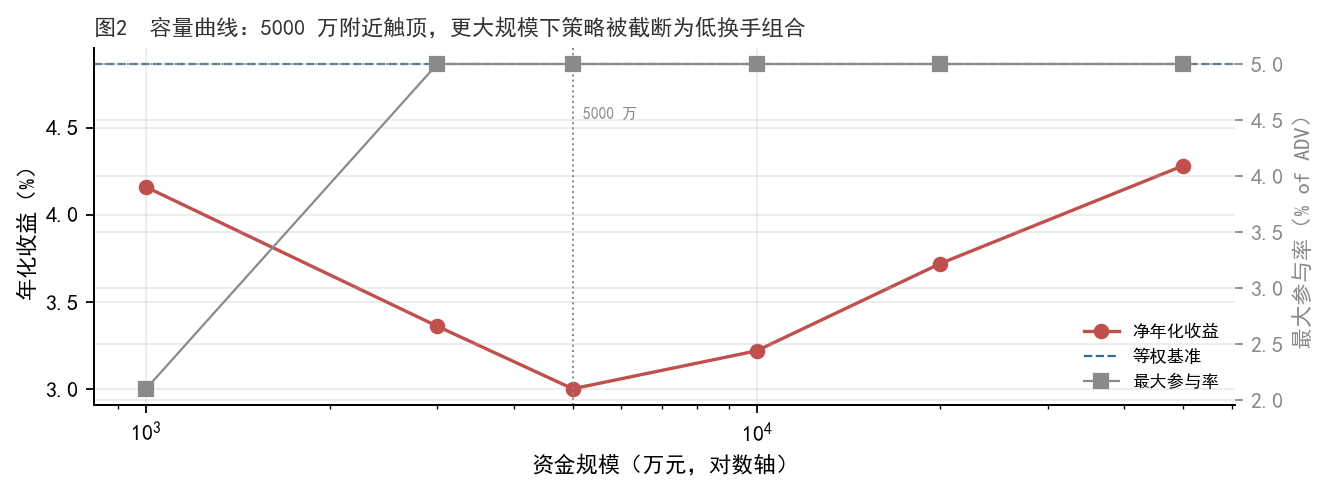

In [9]:

from src.charts import build_all
from IPython.display import Image, display

build_all()
for name in ["fig1_nav.png", "fig2_flowmap.png", "fig3_review2026.png", "fig4_capacity.png"]:
    display(Image(filename=f"output/figures/{name}"))



# 结论（与 results.json 一致）

- 公开 ETF 数据下，基础因子与综合因子都**没有复现**研报的 21.97% / 22.63% 年化与双位数超额；
  样本区间、标的池与数据口径（Wind 主动买卖 vs 量价代理）是主要差异来源。
- 5000 万元、参与率 ≤5% ADV、含佣金/价差/冲击后，收益进一步被成本与容量侵蚀；
  容量不是静态比例，而是“流动性差的行业先被挤出”的动态过程。
- 研报最可复用的不是五因子合成，而是**净流入为正比例**这一广度指标：
  2026-06-30 见顶、07-06 骤降，随后半导体 7 月 −34%。广度比强度更早反映分歧。
- 方法层面最大的警示是**识别问题**：流向图未知量远多于方程，
  “拟合误差 <5‰”不能当作模型有效的证据；最小二范数解是假设，不是事实。
